Part a

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

random.seed(69)
np.random.seed(69)

def load_graph_from_file(filepath):
    graph = {}
    with open(filepath, 'r') as file:
        for line in file:
            node1, node2 = map(int, line.strip().split())
            if node1 not in graph:
                graph[node1] = []
            if node2 not in graph:
                graph[node2] = []
            graph[node1].append(node2)
            graph[node2].append(node1)
    return graph

def get_graph_info(graph):
    num_nodes = len(graph)
    num_edges = sum(len(neighbors) for neighbors in graph.values()) // 2
    return num_nodes, num_edges

# Loading real-world graph
filepath = 'F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Analysis of Complex Networks/Assignments/HW1/Answer/input/P1/realworldgraph.txt'
real_world_graph = load_graph_from_file(filepath)

#Getting number of nodes and edges
num_nodes, num_edges = get_graph_info(real_world_graph)
print(f"Number of nodes: {num_nodes}, Number of edges: {num_edges}")

Number of nodes: 5242, Number of edges: 28980


Part b

In [2]:
def find_largest_connected_component(graph):
    visited = set()
    def dfs(node):
        stack = [node]
        component = []
        while stack:
            current = stack.pop()
            if current not in visited:
                visited.add(current)
                component.append(current)
                stack.extend(graph[current])
        return component   
    largest_cc = []
    for node in graph:
        if node not in visited:
            component = dfs(node)
            if len(component) > len(largest_cc):
                largest_cc = component
    
    return largest_cc

largest_cc = find_largest_connected_component(real_world_graph)
print(f"Number of nodes in largest connected component: {len(largest_cc)}")

largest_cc_edges = sum(len(real_world_graph[node]) for node in largest_cc) // 2
print(f"Number of edges in largest connected component: {largest_cc_edges}")

Number of nodes in largest connected component: 4158
Number of edges in largest connected component: 26850


Part c

In [3]:
from collections import deque

def bfs_path_length(graph, start_node):
    visited = {start_node}
    queue = deque([(start_node, 0)])
    total_length = 0
    num_paths = 0
    max_distance = 0
    
    while queue:
        current, distance = queue.popleft()
        total_length += distance
        num_paths += 1
        max_distance = max(max_distance, distance)
        
        for neighbor in graph[current]:
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append((neighbor, distance + 1))
                
    return total_length, num_paths, max_distance

def calculate_average_path_length_and_diameter(graph):
    total_length = 0
    total_paths = 0
    max_diameter = 0
    
    for node in graph:
        length, paths, diameter = bfs_path_length(graph, node)
        total_length += length
        total_paths += paths
        max_diameter = max(max_diameter, diameter)
    
    average_path_length = total_length / total_paths if total_paths > 0 else float('inf')
    return average_path_length, max_diameter

average_path_length, diameter = calculate_average_path_length_and_diameter(real_world_graph)
print(f"Average path length: {average_path_length}")
print(f"Diameter: {diameter}")

Average path length: 6.046681512519032
Diameter: 17


Part d

In [4]:
def generate_er_graph(num_nodes, num_edges):
    graph = {i: [] for i in range(num_nodes)}
    edges = set()
    while len(edges) < num_edges:
        node1 = random.randint(0, num_nodes - 1)
        node2 = random.randint(0, num_nodes - 1)
        if node1 != node2 and (node1, node2) not in edges and (node2, node1) not in edges:
            edges.add((node1, node2))
            graph[node1].append(node2)
            graph[node2].append(node1)
    return graph

er_graph = generate_er_graph(num_nodes, num_edges)

Part e

In [5]:
def generate_small_world_graph(num_nodes, k, p):
    from itertools import combinations
    graph = {i: [] for i in range(num_nodes)}
    # Creating a ring lattice
    for i in range(num_nodes):
        for j in range(1, k // 2 + 1):
            neighbor = (i + j) % num_nodes
            graph[i].append(neighbor)
            graph[neighbor].append(i)
    # Rewiring edges with probability p
    for i in range(num_nodes):
        for j in range(1, k // 2 + 1):
            if random.random() < p:
                current_neighbor = (i + j) % num_nodes
                graph[i].remove(current_neighbor)
                graph[current_neighbor].remove(i)
                new_neighbor = random.choice([x for x in range(num_nodes) if x != i and x not in graph[i]])
                graph[i].append(new_neighbor)
                graph[new_neighbor].append(i)
    return graph

small_world_graph = generate_small_world_graph(num_nodes, k=4, p=0.2)

Part f

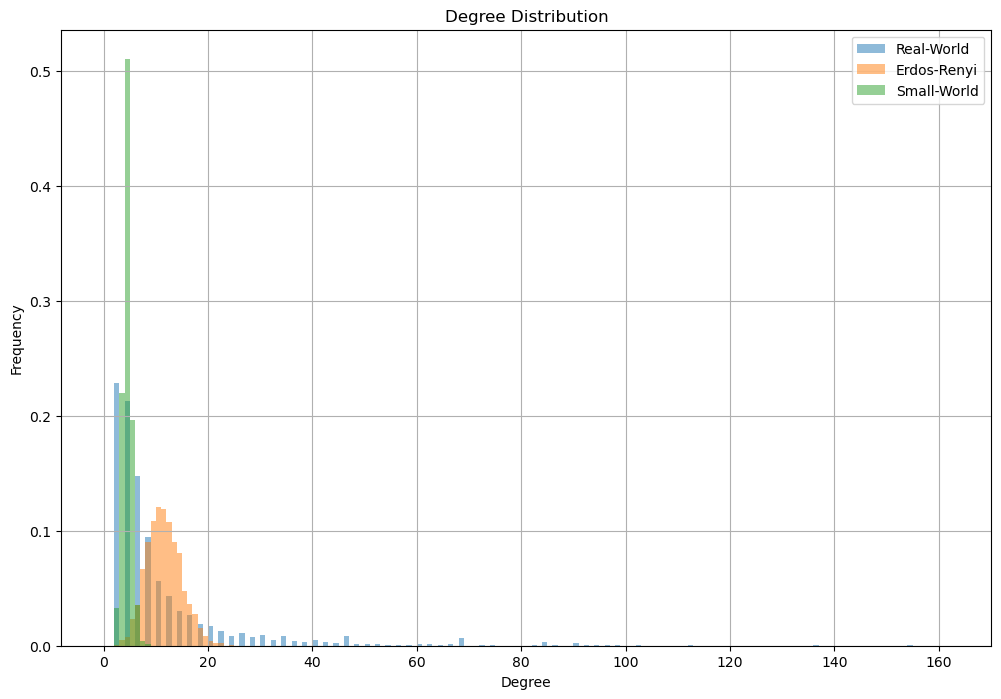

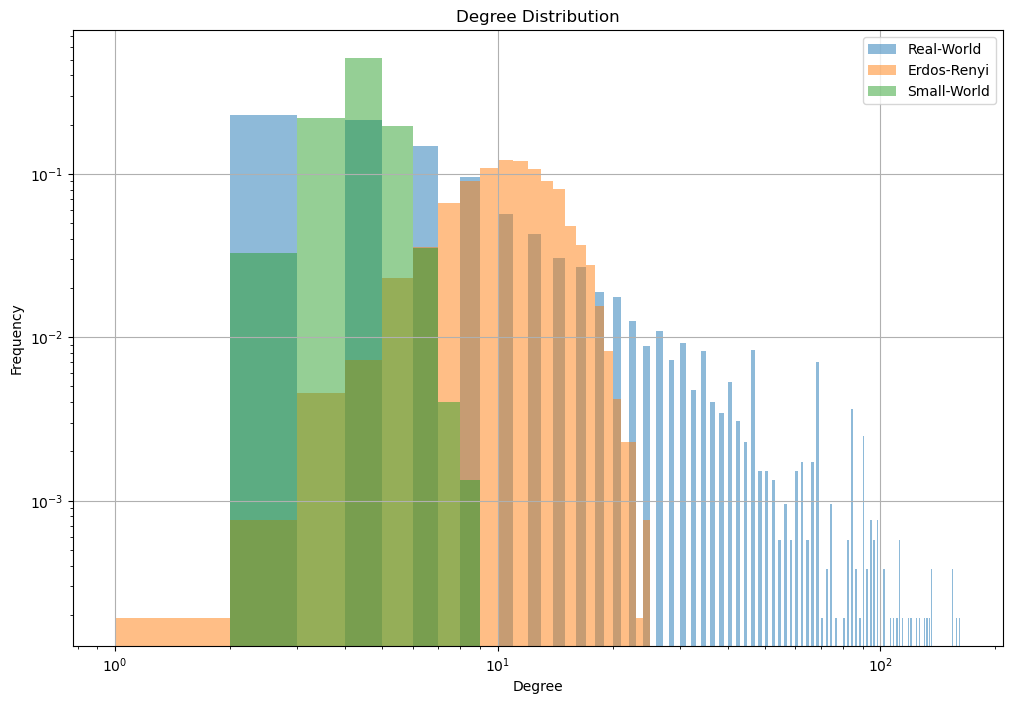

In [6]:
def plot_degree_distribution(graphs, labels, log_scale=False):
    plt.figure(figsize=(12, 8))
    for graph, label in zip(graphs, labels):
        degrees = [len(neighbors) for neighbors in graph.values()]
        plt.hist(degrees, bins=range(max(degrees) + 1), alpha=0.5, label=label, density=True)
    if log_scale:
        plt.xscale('log')
        plt.yscale('log')
    plt.xlabel('Degree')
    plt.ylabel('Frequency')
    plt.title('Degree Distribution')
    plt.legend()
    plt.grid(True)
    plt.show()

# Ploting 
plot_degree_distribution([real_world_graph, er_graph, small_world_graph], ['Real-World', 'Erdos-Renyi', 'Small-World'])
plot_degree_distribution([real_world_graph, er_graph, small_world_graph], ['Real-World', 'Erdos-Renyi', 'Small-World'], log_scale=True)

Part g

In [7]:
def calculate_average_clustering_coefficient(graph):
    triangles = 0
    triplets = 0
    for node in graph:
        neighbors = graph[node]
        if len(neighbors) < 2:
            continue
        local_triplets = len(neighbors) * (len(neighbors) - 1) / 2
        local_triangles = sum(1 for i in neighbors for j in neighbors if i != j and j in graph[i]) / 2
        triplets += local_triplets
        triangles += local_triangles
    return triangles / triplets if triplets > 0 else 0

real_world_clustering = calculate_average_clustering_coefficient(real_world_graph)
er_graph_clustering = calculate_average_clustering_coefficient(er_graph)
small_world_clustering = calculate_average_clustering_coefficient(small_world_graph)

print(f"Average clustering coefficient (Real-World): {real_world_clustering}")
print(f"Average clustering coefficient (Erdos-Renyi): {er_graph_clustering}")
print(f"Average clustering coefficient (Small-World): {small_world_clustering}")

Average clustering coefficient (Real-World): 0.6107108073580936
Average clustering coefficient (Erdos-Renyi): 0.0020506578023315697
Average clustering coefficient (Small-World): 0.23642621969470218
